<a href="https://colab.research.google.com/github/SrustiUB/Data-Science/blob/main/MOPSO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.1/90.1 kB 4.4 MB/s eta 0:00:00
Iteration  25 | Pareto portfolios: 92
Iteration  50 | Pareto portfolios: 80
Iteration  75 | Pareto portfolios: 83
Iteration 100 | Pareto portfolios: 88
Iteration 125 | Pareto portfolios: 100
Iteration 150 | Pareto portfolios: 100

================ MOPSO PORTFOLIO ================

RELIANCE.NS    : 37.80%
HDFCBANK.NS    : 0.13%
ICICIBANK.NS   : 0.12%
INFY.NS        : 7.09%
TCS.NS         : 0.02%
ITC.NS         : 6.71%
LT.NS          : 17.59%
SBIN.NS        : 0.64%
BHARTIARTL.NS  : 29.91%
HINDUNILVR.NS  : 0.00%

---------------- Portfolio Metrics ----------------
Return            : 0.2918
Volatility        : 0.1727
CVaR              : 0.3656
Turnover          : 1.1058
Diversification   : 3.6659
Sharpe            : 1.6901


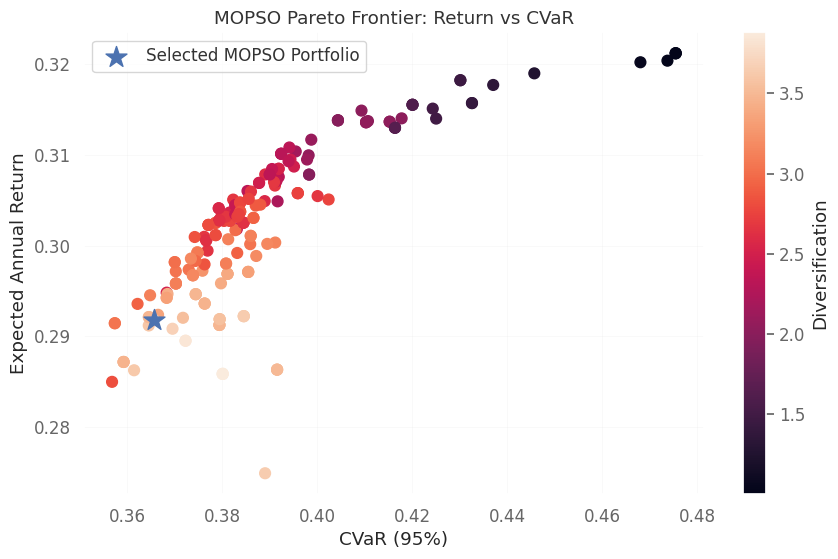

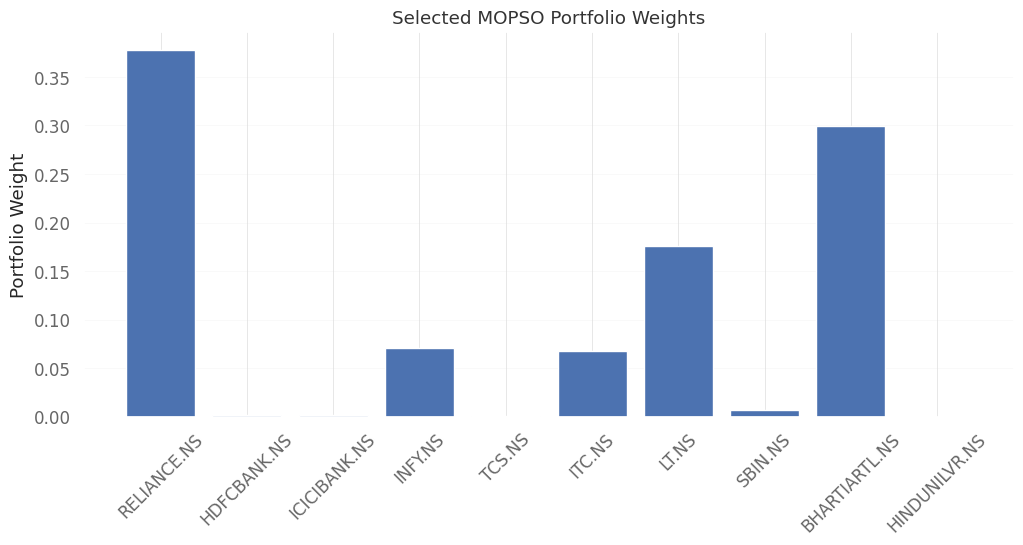


================ PARETO SOLUTIONS ================

     Return  Volatility    CVaR  Turnover  Diversification  Sharpe  \
150  0.2918      0.1727  0.3656    1.1058           3.6659  1.6901   
90   0.2921      0.1722  0.3646    1.0690           3.4761  1.6961   
187  0.2921      0.1722  0.3646    1.0690           3.4761  1.6961   
20   0.2912      0.1722  0.3645    1.1095           3.5895  1.6910   
44   0.2945      0.1731  0.3648    1.0670           3.1257  1.7017   
126  0.2895      0.1751  0.3723    1.1289           3.8369  1.6533   
57   0.2895      0.1751  0.3723    1.1289           3.8369  1.6533   
34   0.2908      0.1749  0.3695    1.1347           3.6850  1.6626   
72   0.2913      0.1783  0.3794    1.0587           3.4837  1.6332   
136  0.2913      0.1783  0.3794    1.0587           3.4837  1.6332   

     MOPSO_Score  
150       3.1290  
90        3.1265  
187       3.1265  
20        3.0927  
44        3.0572  
126       3.0514  
57        3.0514  
34        3.0427  
72   

In [ ]:
# ================================================================
# MOPSO: MULTI-OBJECTIVE PORTFOLIO OPTIMISATION
# Objectives: Return ↑ | CVaR ↓ | Turnover ↓ | Diversification ↑
# ================================================================

!pip -q install yfinance quantstats

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import quantstats as qs

np.random.seed(42)

# ----------------------------- DATA ------------------------------

tickers = [
    "RELIANCE.NS","HDFCBANK.NS","ICICIBANK.NS","INFY.NS",
    "TCS.NS","ITC.NS","LT.NS","SBIN.NS",
    "BHARTIARTL.NS","HINDUNILVR.NS"
]

prices = yf.download(
    tickers,
    start="2021-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)["Close"].dropna()

returns = prices.pct_change().dropna()

n_assets = len(tickers)

# Annualised expected returns
mu = returns.mean().values * 252

# Covariance matrix
cov = returns.cov().values * 252

# Equal-weight benchmark for turnover
benchmark = np.ones(n_assets) / n_assets


# ------------------------- OBJECTIVES ----------------------------

def portfolio_metrics(w):

    port_ret = np.dot(w, mu)

    # Portfolio volatility
    port_vol = np.sqrt(w @ cov @ w)

    # Daily portfolio returns
    port_daily = returns.values @ w

    # 95% CVaR
    var95 = np.percentile(port_daily, 5)
    cvar = -port_daily[port_daily <= var95].mean() * np.sqrt(252)

    # Turnover relative to equal-weight portfolio
    turnover = np.sum(np.abs(w - benchmark))

    # Herfindahl concentration
    hhi = np.sum(w ** 2)

    # Diversification score
    diversification = 1 / hhi

    # Sharpe (used only for reporting)
    sharpe = port_ret / port_vol

    return {
        "return": port_ret,
        "volatility": port_vol,
        "cvar": cvar,
        "turnover": turnover,
        "diversification": diversification,
        "sharpe": sharpe
    }


# ---------------------- PARETO DOMINANCE -------------------------

# Objectives are converted so that ALL are maximised:
# return ↑
# CVaR ↓ -> -CVaR
# turnover ↓ -> -turnover
# diversification ↑

def objective_vector(w):

    m = portfolio_metrics(w)

    return np.array([
        m["return"],
        -m["cvar"],
        -m["turnover"],
        m["diversification"]
    ])


def dominates(a, b):
    return np.all(a >= b) and np.any(a > b)


def pareto_front(particles):

    objs = np.array([objective_vector(w) for w in particles])

    mask = np.ones(len(particles), dtype=bool)

    for i in range(len(particles)):
        if not mask[i]:
            continue

        for j in range(len(particles)):
            if i != j and dominates(objs[j], objs[i]):
                mask[i] = False
                break

    return particles[mask], objs[mask]


# --------------------------- MOPSO -------------------------------

n_particles = 80
n_iterations = 150

w_inertia = 0.72
c1 = 1.5
c2 = 1.5

# Particle positions
X = np.random.dirichlet(np.ones(n_assets), n_particles)

# Particle velocities
V = np.random.normal(0, 0.02, (n_particles, n_assets))

# Personal best
P = X.copy()
P_obj = np.array([objective_vector(x) for x in P])

# Pareto archive
archive = []

for iteration in range(n_iterations):

    # Update personal best
    for i in range(n_particles):

        current_obj = objective_vector(X[i])

        if dominates(current_obj, P_obj[i]):
            P[i] = X[i].copy()
            P_obj[i] = current_obj.copy()

        elif not dominates(P_obj[i], current_obj):

            # Keep either solution randomly when non-dominated
            if np.random.rand() < 0.5:
                P[i] = X[i].copy()
                P_obj[i] = current_obj.copy()

    # Combine current swarm + personal best
    candidates = np.vstack([X, P])

    # Pareto archive
    archive_particles, archive_obj = pareto_front(candidates)

    # Limit archive size
    if len(archive_particles) > 100:
        idx = np.random.choice(
            len(archive_particles),
            100,
            replace=False
        )
        archive_particles = archive_particles[idx]
        archive_obj = archive_obj[idx]

    # Update particles
    for i in range(n_particles):

        # Random leader from Pareto archive
        leader = archive_particles[
            np.random.randint(len(archive_particles))
        ]

        r1 = np.random.rand(n_assets)
        r2 = np.random.rand(n_assets)

        V[i] = (
            w_inertia * V[i]
            + c1 * r1 * (P[i] - X[i])
            + c2 * r2 * (leader - X[i])
        )

        X[i] += V[i]

        # Long-only constraint
        X[i] = np.maximum(X[i], 0)

        # Fully invested constraint
        if X[i].sum() == 0:
            X[i] = np.ones(n_assets) / n_assets
        else:
            X[i] /= X[i].sum()

    if (iteration + 1) % 25 == 0:
        print(
            f"Iteration {iteration+1:3d} | "
            f"Pareto portfolios: {len(archive_particles)}"
        )


# ---------------------- FINAL PARETO SET --------------------------

pareto_weights, pareto_objectives = pareto_front(
    np.vstack([X, P, archive_particles])
)

results = []

for w in pareto_weights:

    m = portfolio_metrics(w)

    results.append({
        "Return": m["return"],
        "Volatility": m["volatility"],
        "CVaR": m["cvar"],
        "Turnover": m["turnover"],
        "Diversification": m["diversification"],
        "Sharpe": m["sharpe"]
    })

results = pd.DataFrame(results)

# ----------------------- BALANCED PORTFOLIO -----------------------

# Normalised objective scores
score = (
    (results["Return"] - results["Return"].min()) /
    (results["Return"].max() - results["Return"].min() + 1e-12)

    +

    (results["CVaR"].max() - results["CVaR"]) /
    (results["CVaR"].max() - results["CVaR"].min() + 1e-12)

    +

    (results["Turnover"].max() - results["Turnover"]) /
    (results["Turnover"].max() - results["Turnover"].min() + 1e-12)

    +

    (results["Diversification"] - results["Diversification"].min()) /
    (results["Diversification"].max() - results["Diversification"].min() + 1e-12)
)

best_idx = score.idxmax()
best_weights = pareto_weights[best_idx]

results["MOPSO_Score"] = score


# ----------------------- RESULTS ---------------------------------

print("\n================ MOPSO PORTFOLIO ================\n")

for ticker, weight in zip(tickers, best_weights):
    print(f"{ticker:15s}: {weight:.2%}")

best = results.iloc[best_idx]

print("\n---------------- Portfolio Metrics ----------------")

for col in [
    "Return",
    "Volatility",
    "CVaR",
    "Turnover",
    "Diversification",
    "Sharpe"
]:
    print(f"{col:18s}: {best[col]:.4f}")


# ---------------------- PARETO FRONTIER ---------------------------

plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    results["CVaR"],
    results["Return"],
    c=results["Diversification"],
    s=60
)

plt.scatter(
    best["CVaR"],
    best["Return"],
    marker="*",
    s=250,
    label="Selected MOPSO Portfolio"
)

plt.xlabel("CVaR (95%)")
plt.ylabel("Expected Annual Return")
plt.title("MOPSO Pareto Frontier: Return vs CVaR")
plt.colorbar(scatter, label="Diversification")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


# ----------------------- WEIGHTS ---------------------------------

plt.figure(figsize=(12, 5))

plt.bar(tickers, best_weights)

plt.xticks(rotation=45)
plt.ylabel("Portfolio Weight")
plt.title("Selected MOPSO Portfolio Weights")
plt.grid(axis="y", alpha=0.25)

plt.show()


# -------------------- TOP PARETO PORTFOLIOS ----------------------

print("\n================ PARETO SOLUTIONS ================\n")

print(
    results.sort_values(
        "MOPSO_Score",
        ascending=False
    ).head(10).round(4)
)